In [1]:
!pip install torchviz
! pip install torchinfo

In [2]:
import random
import os
import torch
import time
import imblearn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch.nn as nn
import seaborn as sns

import torchinfo
from sklearn.decomposition import PCA
from torchviz import make_dot
from sklearn.preprocessing import LabelEncoder
from transformers import AutoTokenizer, AutoModel
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, precision_score, recall_score, f1_score, accuracy_score
from sentence_transformers import SentenceTransformer
from collections import Counter
from sklearn.metrics import confusion_matrix
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_auc_score, roc_curve

In [3]:
def set_seed(seed_value=42):
    """Fungsi untuk mengatur seed agar hasil eksperimen dapat direproduksi."""
    random.seed(seed_value)
    os.environ['PYTHONHASHSEED'] = str(seed_value)
    np.random.seed(seed_value)
    torch.manual_seed(seed_value)
    torch.cuda.manual_seed(seed_value)
    torch.cuda.manual_seed_all(seed_value)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

# LANGSUNG DIPANGGIL DI SINI
set_seed(42)

In [4]:
# Load Data dan Cek Data
from google.colab import drive
drive.mount('/content/drive')

data = pd.read_csv('/content/drive/MyDrive/MAGANG BRIN/Dataset/Data_Epidemi_processed.csv')
data

Mounted at /content/drive


,title,Sentiment,title_case_folding,title_cleaned,title_tokenization
0,Kemkes: 67 dari 69 WNI ABK Diamond Princess ne...,2,kemkes: 67 dari 69 wni abk diamond princess ne...,kemkes 67 dari 69 wni abk diamond princess neg...,"['kemkes', '67', 'dari', '69', 'wni', 'abk', '..."
1,1.925 pasien COVID dirawat di RS Wisma Atlet K...,0,1.925 pasien covid dirawat di rs wisma atlet k...,1925 pasien covid dirawat di rs wisma atlet ke...,"['1925', 'pasien', 'covid', 'dirawat', 'di', '..."
2,Jubir: Kasus positif COVID-19 DIY bertambah 59...,0,jubir: kasus positif covid-19 diy bertambah 59...,jubir kasus positif covid19 diy bertambah 59 o...,"['jubir', 'kasus', 'positif', 'covid19', 'diy'..."
3,Jaktim fungsikan gedung Karang Taruna untuk is...,1,jaktim fungsikan gedung karang taruna untuk is...,jaktim fungsikan gedung karang taruna untuk is...,"['jaktim', 'fungsikan', 'gedung', 'karang', 't..."
4,"Omicron terdeteksi, NTB klaim situasi COVID-19...",1,"omicron terdeteksi, ntb klaim situasi covid-19...",omicron terdeteksi ntb klaim situasi covid19 m...,"['omicron', 'terdeteksi', 'ntb', 'klaim', 'sit..."
...,...,...,...,...,...
17439,Penambahan kasus COVID-19 terbanyak di Jakarta...,0,penambahan kasus covid-19 terbanyak di jakarta...,penambahan kasus covid19 terbanyak di jakarta ...,"['penambahan', 'kasus', 'covid19', 'terbanyak'..."
17440,"Klaster Persiapan Hajatan Bantul, 70 orang Pos...",0,"klaster persiapan hajatan bantul, 70 orang pos...",klaster persiapan hajatan bantul 70 orang posi...,"['klaster', 'persiapan', 'hajatan', 'bantul', ..."
17441,Eks Direktur WHO Minta Pemerintah Serius Dalam...,1,eks direktur who minta pemerintah serius dalam...,eks direktur who minta pemerintah serius dalam...,"['eks', 'direktur', 'who', 'minta', 'pemerinta..."
17442,Pasien positif COVID-19 di RSKD Duren Sawit pe...,0,pasien positif covid-19 di rskd duren sawit pe...,pasien positif covid19 di rskd duren sawit per...,"['pasien', 'positif', 'covid19', 'di', 'rskd',..."


In [5]:
# Melakukan Defini Variabel
X = data['title_cleaned'].tolist()
y = data['Sentiment'].tolist()

In [6]:
# Distribusi Awal
data['Sentiment'].value_counts()

,count
Sentiment,
0,10864
2,3992
1,2588


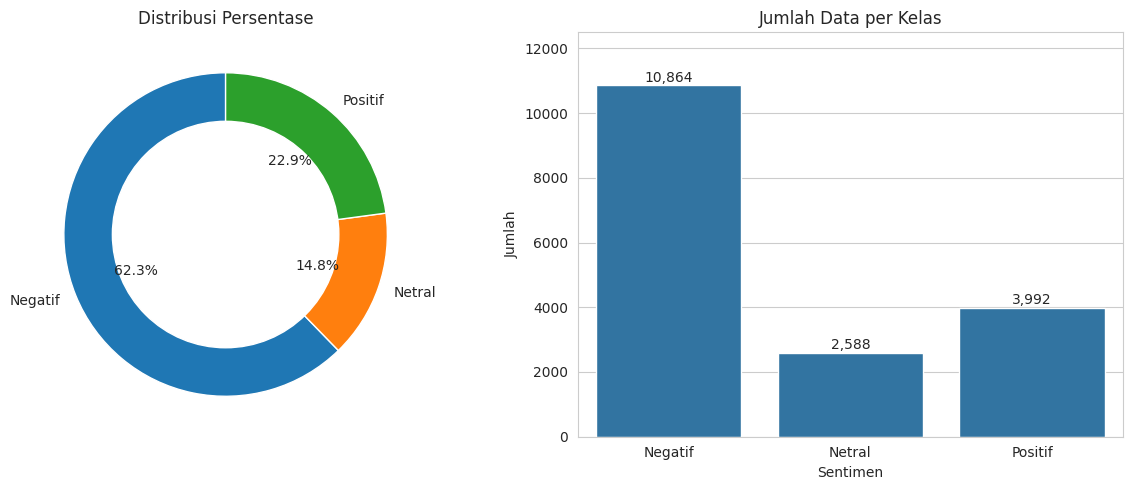

In [7]:
# Grafik Distribusi Awal
sns.set_style("whitegrid")
plt.rcParams['font.size'] = 10

# Urutkan label biar konsisten
counts = data['Sentiment'].value_counts().sort_index()
labels = counts.index
sizes = counts.values

# Mapping biar lebih readable
label_names = {0: 'Negatif', 1: 'Netral', 2: 'Positif'}
labels_readable = [label_names[i] for i in labels]

# Figure
fig, ax = plt.subplots(1, 2, figsize=(12,5))

# =========================
# PIE CHART (DONUT STYLE)
# =========================
wedges, texts, autotexts = ax[0].pie(
    sizes,
    labels=labels_readable,
    autopct='%1.1f%%',
    startangle=90,
    wedgeprops={'edgecolor': 'white'}
)

# Bikin donut (biar lebih modern)
centre_circle = plt.Circle((0,0),0.70,fc='white')
ax[0].add_artist(centre_circle)

ax[0].set_title('Distribusi Persentase')

# =========================
# BAR CHART (JUMLAH DATA)
# =========================
bars = sns.barplot(x=labels_readable, y=sizes, ax=ax[1])

ax[1].set_title('Jumlah Data per Kelas')
ax[1].set_ylabel('Jumlah')
ax[1].set_xlabel('Sentimen')

# Perbaiki posisi angka (tidak nabrak)
for i, v in enumerate(sizes):
    ax[1].text(i, v + max(sizes)*0.01, f'{v:,}', ha='center', fontsize=10)

# Biar nggak kepotong
ax[1].set_ylim(0, max(sizes)*1.15)

plt.tight_layout()
plt.show()

Max word length: 28
Min word length: 3
Average word length: 8.664125200642054


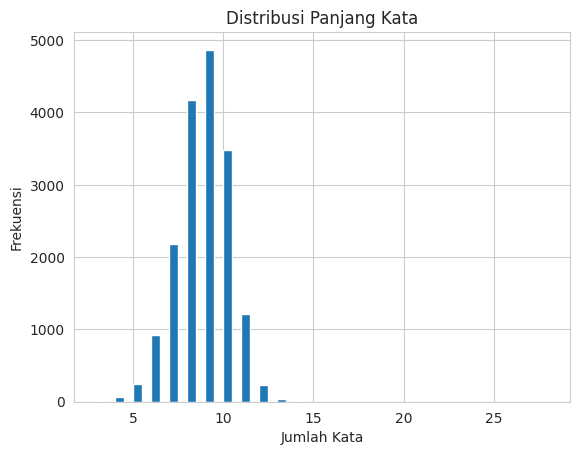

In [8]:
# Melihat banyak data dalam setiap data
word_lengths = [len(text.split()) for text in X]

print("Max word length:", max(word_lengths))
print("Min word length:", min(word_lengths))
print("Average word length:", sum(word_lengths)/len(word_lengths))
plt.hist(word_lengths, bins=50)
plt.title("Distribusi Panjang Kata")
plt.xlabel("Jumlah Kata")
plt.ylabel("Frekuensi")
plt.show()

In [9]:
# Load tokenizer
model_name = "indobenchmark/indobert-base-p1"
tokenizer = AutoTokenizer.from_pretrained(model_name)  # untuk mengubah teks menjadi token ID

config.json:   0%|          | 0.00/1.53k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/229k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Max token length: 33
Min token length: 5
Average token length: 11.364022013299701


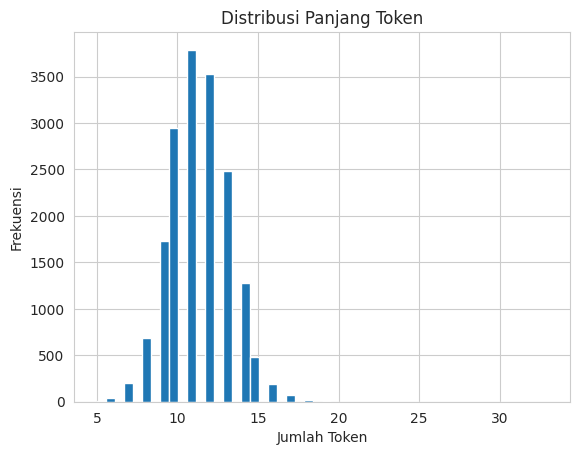

In [10]:
# Melihat panjang maksimal token data
token_lengths = [len(tokenizer.tokenize(text)) for text in X]

print("Max token length:", max(token_lengths))
print("Min token length:", min(token_lengths))
print("Average token length:", sum(token_lengths)/len(token_lengths))

plt.hist(token_lengths, bins=50)
plt.title("Distribusi Panjang Token")
plt.xlabel("Jumlah Token")
plt.ylabel("Frekuensi")
plt.show()

In [11]:
# Dataset Class

class SentimentDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=24):
        self.texts = texts
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self): #ambil jumlah data
        return len(self.texts)

    def __getitem__(self, idx): #mengambil 1 data berdasarkan index
        encoding = self.tokenizer(
            self.texts[idx],
            padding='max_length',#data dibuat panjang yang sama
            truncation=True, #pemotongan teks jika terlalu panjang
            max_length=self.max_len, #batas maksimum panjang token
            return_tensors='pt'#output bentuk PyTorch
        )

        return {
            'input_ids': encoding['input_ids'].squeeze(0),#angka yang merepresentasikan kata
            'attention_mask': encoding['attention_mask'].squeeze(0), #penanda jika 1 = token asli, 0 = padding
            'labels': torch.tensor(self.labels[idx], dtype=torch.long),

        }

In [12]:
# Model
class IndoBERT_CNN_BiLSTM(nn.Module):
    def __init__(self, bert, num_classes=3):
        super().__init__()
        self.bert = bert #pretrained model (IndoBERT)

        # CNN -> untuk mengambil pola lokal dan mengurangi dimensi
        self.conv = nn.Conv1d(768, 128, kernel_size=3, padding=1)
        self.relu = nn.ReLU() #aktivasi non-linear dengan tujuan menghilangkan nilai negatif
        self.pool = nn.MaxPool1d(kernel_size=2) #mengambil nilai max dari setiap 2 langkah

        # BiLSTM
        self.bilstm = nn.LSTM(
            input_size=128, #input fitur yang masuk ke LSTM (harus sesuai dengan output CNN)
            hidden_size=64, #ukuran 'memori' (menyimpan informasi dalam 64 dimensi) -> 128/2 = 64 masing-masing forward dan backward
            batch_first=True,
            bidirectional=True
        )

        # Global Pooling -> meringkas seluruh seq menjadi 1 nilai per fitur
        self.global_pool = nn.AdaptiveMaxPool1d(1) #input memiliki panjang berbeda namun output tetap 1

        # Dense
        self.fc1 = nn.Linear(128, 64) #mengubah 128 fitur ke 64 fitur
        self.dropout = nn.Dropout(0.3) #mematikan 30% neuron secara acak saat training untuk mencegah overfitting
        self.fc2 = nn.Linear(64, num_classes) #klasifikasi dari 64 fitur diambil 3 fitur saja

    def forward(self, input_ids, attention_mask):
        # IndoBERT
        bert_out = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        x = bert_out.last_hidden_state  # (batch, seq_len, 768)

        # CNN
        x = x.permute(0, 2, 1)          # (batch, 768, seq_len)
        x = self.conv(x) #lihat 3 kata/token sekaligus dan ekstrak pola lokal
        x = self.relu(x) #menghilangkan nilai negatif (aktivasi non-linear)
        x = self.pool(x) #mengambil nilai max dari setiap 2 langkah
        #menghasilkan output (batch, 128, seq_len/2)

        # BiLSTM
        x = x.permute(0, 2, 1)          # (batch, seq_len/2, 128)
        x, _ = self.bilstm(x)           # (batch, seq_len/2, 128)

        # Global pooling
        x = x.permute(0, 2, 1)          # (batch, 128, seq_len/2)
        x = self.global_pool(x)         # (batch, 128, 1)
        x = x.squeeze(-1) #menghapus dimensi yang tidak perlu  # (batch, 128)

        # Dense
        x = self.relu(self.fc1(x)) #aktivasi non-linear dengan tujuan agar belajar fitur yang lebih kompleks
        x = self.dropout(x)
        x = self.fc2(x)

        return x

In [13]:
# Preview Arsitektur Model
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

_preview_bert = AutoModel.from_pretrained(model_name)
_preview_model = IndoBERT_CNN_BiLSTM(_preview_bert).to(device)
torchinfo.summary(_preview_model, input_size=[(1, 24), (1, 24)], dtypes=[torch.long, torch.long])

del _preview_bert, _preview_model
torch.cuda.empty_cache()

pytorch_model.bin:   0%|          | 0.00/498M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/498M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

In [14]:
# ================= STRATIFIED K-FOLD CROSS VALIDATION =================
from sklearn.utils.class_weight import compute_class_weight
from sklearn.model_selection import StratifiedKFold

embedder = SentenceTransformer('all-MiniLM-L6-v2')
y = np.array(y)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

fold = 1
performance = []

train_loss_history = []
val_loss_history = []

train_acc_history = []
val_acc_history = []

EPOCHS = 25

all_y_true = []
all_y_pred = []
all_y_probs = []

for train_index, test_index in skf.split(X, y):

    print(f"\n{'='*30} FOLD {fold} {'='*30}")
    fold_start_time = time.time()

    # ==========================================================
    # STEP 1 : Split fold -> train_full dan test
    # ==========================================================
    X_train_full = [X[i] for i in train_index]
    y_train_full = [y[i] for i in train_index]

    X_test = [X[i] for i in test_index]
    y_test = [y[i] for i in test_index]

    # ==========================================================
    # STEP 2 : Split train_full -> train dan validation
    # ==========================================================
    X_train, X_val, y_train, y_val = train_test_split(
        X_train_full,
        y_train_full,
        test_size=0.05,
        stratify=y_train_full,
        random_state=42
    )

    # ==========================================================
    # STEP 3 : DataLoader
    # ==========================================================

    train_loader = DataLoader(
        SentimentDataset(X_train, y_train, tokenizer),
        batch_size=16,
        shuffle=True
    )

    val_loader = DataLoader(
        SentimentDataset(X_val, y_val, tokenizer),
        batch_size=16
    )

    test_loader = DataLoader(
        SentimentDataset(X_test, y_test, tokenizer),
        batch_size=16
    )

    # ==========================================================
    # STEP 4 : Model Setup
    # ==========================================================
    set_seed(42)

    bert_model = AutoModel.from_pretrained(model_name)
    model = IndoBERT_CNN_BiLSTM(bert_model).to(device)

    class_weights = compute_class_weight(
        class_weight='balanced',
        classes=np.unique(y_train),
        y=y_train
    )

    weights = torch.tensor(
        class_weights,
        dtype=torch.float
    ).to(device)

    criterion = nn.CrossEntropyLoss(weight=weights)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=2e-5
    )

    # history per fold
    fold_train_loss = []
    fold_val_loss = []

    fold_train_acc = []
    fold_val_acc = []


    # ==========================================================
    # STEP 5 : Training + Validation
    # ==========================================================
    for epoch in range(EPOCHS):

        # ---------------- TRAIN ----------------
        model.train()

        total_loss = 0
        correct_train = 0
        total_train = 0

        for batch in train_loader:

            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels = batch['labels'].to(device)

            optimizer.zero_grad()

            outputs = model(input_ids, attention_mask)

            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            total_loss += loss.item()

            preds = torch.argmax(outputs, dim=1)

            correct_train += (preds == labels).sum().item()
            total_train += labels.size(0)

        avg_train_loss = total_loss / len(train_loader)
        train_acc = correct_train / total_train

        # ---------------- VALIDATION ----------------
        model.eval()

        val_loss = 0
        correct_val = 0
        total_val = 0

        with torch.no_grad():

            for batch in val_loader:

                input_ids = batch['input_ids'].to(device)
                attention_mask = batch['attention_mask'].to(device)
                labels = batch['labels'].to(device)

                outputs = model(input_ids, attention_mask)

                loss = criterion(outputs, labels)

                val_loss += loss.item()

                preds = torch.argmax(outputs, dim=1)

                correct_val += (preds == labels).sum().item()
                total_val += labels.size(0)

        avg_val_loss = val_loss / len(val_loader)
        val_acc = correct_val / total_val

        # simpan history
        fold_train_loss.append(avg_train_loss)
        fold_val_loss.append(avg_val_loss)

        fold_train_acc.append(train_acc)
        fold_val_acc.append(val_acc)

        print(
            f"Epoch {epoch+1}/{EPOCHS} | "
            f"Train Loss: {avg_train_loss:.4f} | "
            f"Val Loss: {avg_val_loss:.4f} | "
            f"Train Acc: {train_acc:.4f} | "
            f"Val Acc: {val_acc:.4f}"
        )

    # simpan semua fold history
    train_loss_history.append(fold_train_loss)
    val_loss_history.append(fold_val_loss)

    train_acc_history.append(fold_train_acc)
    val_acc_history.append(fold_val_acc)

    # ==========================================================
    # STEP 8 : Final Test Evaluation
    # ==========================================================
    model.eval()

    y_true_fold = []
    y_pred_fold = []
    y_probs_fold = []

    with torch.no_grad():

        for batch in test_loader:

            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels = batch['labels'].to(device)

            outputs = model(input_ids, attention_mask)

            probs = torch.softmax(outputs, dim=1)
            preds = torch.argmax(probs, dim=1)

            y_true_fold.extend(labels.cpu().numpy())
            y_pred_fold.extend(preds.cpu().numpy())
            y_probs_fold.extend(probs.cpu().numpy())

    all_y_true.extend(y_true_fold)
    all_y_pred.extend(y_pred_fold)
    all_y_probs.extend(y_probs_fold)

    # ==========================================================
    # STEP 9 : Metrics
    # ==========================================================
    acc = accuracy_score(y_true_fold, y_pred_fold)

    prec = precision_score(
        y_true_fold,
        y_pred_fold,
        average='macro',
        zero_division=0
    )

    rec = recall_score(
        y_true_fold,
        y_pred_fold,
        average='macro',
        zero_division=0
    )

    f1 = f1_score(
        y_true_fold,
        y_pred_fold,
        average='macro',
        zero_division=0
    )

    fold_time = time.time() - fold_start_time

    print(
        f"\nFold {fold} -> "
        f"Acc: {acc:.4f} | "
        f"Precision: {prec:.4f} | "
        f"Recall: {rec:.4f} | "
        f"F1: {f1:.4f} | "
        f"Waktu: {fold_time/60:.2f} menit"
    )

    performance.append({
        'fold': fold,
        'accuracy': acc,
        'precision': prec,
        'recall': rec,
        'f1': f1
    })

    # cleanup
    del bert_model, model, optimizer, criterion
    torch.cuda.empty_cache()

    fold += 1

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

Epoch 1/25 | Train Loss: 0.6699 | Val Loss: 0.5365 | Train Acc: 0.7807 | Val Acc: 0.8037
Epoch 2/25 | Train Loss: 0.4411 | Val Loss: 0.4853 | Train Acc: 0.8540 | Val Acc: 0.8438
Epoch 3/25 | Train Loss: 0.3454 | Val Loss: 0.4708 | Train Acc: 0.8907 | Val Acc: 0.8553
Epoch 4/25 | Train Loss: 0.2802 | Val Loss: 0.5668 | Train Acc: 0.9144 | Val Acc: 0.8596
Epoch 5/25 | Train Loss: 0.2310 | Val Loss: 0.5577 | Train Acc: 0.9288 | Val Acc: 0.8467
Epoch 6/25 | Train Loss: 0.1861 | Val Loss: 0.5824 | Train Acc: 0.9449 | Val Acc: 0.8582
Epoch 7/25 | Train Loss: 0.1658 | Val Loss: 0.6166 | Train Acc: 0.9536 | Val Acc: 0.8467
Epoch 8/25 | Train Loss: 0.1429 | Val Loss: 0.6438 | Train Acc: 0.9613 | Val Acc: 0.8324
Epoch 9/25 | Train Loss: 0.1336 | Val Loss: 0.6923 | Train Acc: 0.9679 | Val Acc: 0.8410
Epoch 10/25 | Train Loss: 0.1233 | Val Loss: 0.7428 | Train Acc: 0.9684 | Val Acc: 0.8539
Epoch 11/25 | Train Loss: 0.1046 | Val Loss: 0.8493 | Train Acc: 0.9751 | Val Acc: 0.8524
Epoch 12/25 | Train

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Epoch 1/25 | Train Loss: 0.6815 | Val Loss: 0.5961 | Train Acc: 0.7759 | Val Acc: 0.8424
Epoch 2/25 | Train Loss: 0.4541 | Val Loss: 0.4869 | Train Acc: 0.8524 | Val Acc: 0.8424
Epoch 3/25 | Train Loss: 0.3466 | Val Loss: 0.5083 | Train Acc: 0.8912 | Val Acc: 0.8582
Epoch 4/25 | Train Loss: 0.2828 | Val Loss: 0.5863 | Train Acc: 0.9091 | Val Acc: 0.8610
Epoch 5/25 | Train Loss: 0.2298 | Val Loss: 0.5198 | Train Acc: 0.9312 | Val Acc: 0.8782
Epoch 6/25 | Train Loss: 0.1981 | Val Loss: 0.5311 | Train Acc: 0.9418 | Val Acc: 0.8510
Epoch 7/25 | Train Loss: 0.1763 | Val Loss: 0.5808 | Train Acc: 0.9495 | Val Acc: 0.8496
Epoch 8/25 | Train Loss: 0.1438 | Val Loss: 0.7315 | Train Acc: 0.9581 | Val Acc: 0.8639
Epoch 9/25 | Train Loss: 0.1307 | Val Loss: 0.6561 | Train Acc: 0.9636 | Val Acc: 0.8610
Epoch 10/25 | Train Loss: 0.1233 | Val Loss: 0.7050 | Train Acc: 0.9669 | Val Acc: 0.8711
Epoch 11/25 | Train Loss: 0.1189 | Val Loss: 0.7303 | Train Acc: 0.9671 | Val Acc: 0.8610
Epoch 12/25 | Train

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Epoch 1/25 | Train Loss: 0.6759 | Val Loss: 0.4722 | Train Acc: 0.7903 | Val Acc: 0.8711
Epoch 2/25 | Train Loss: 0.4535 | Val Loss: 0.4460 | Train Acc: 0.8570 | Val Acc: 0.8725
Epoch 3/25 | Train Loss: 0.3537 | Val Loss: 0.4620 | Train Acc: 0.8892 | Val Acc: 0.8868
Epoch 4/25 | Train Loss: 0.2825 | Val Loss: 0.4700 | Train Acc: 0.9107 | Val Acc: 0.8711
Epoch 5/25 | Train Loss: 0.2288 | Val Loss: 0.5235 | Train Acc: 0.9286 | Val Acc: 0.8739
Epoch 6/25 | Train Loss: 0.1953 | Val Loss: 0.5946 | Train Acc: 0.9404 | Val Acc: 0.8682
Epoch 7/25 | Train Loss: 0.1713 | Val Loss: 0.6040 | Train Acc: 0.9465 | Val Acc: 0.8453
Epoch 8/25 | Train Loss: 0.1437 | Val Loss: 0.6479 | Train Acc: 0.9562 | Val Acc: 0.8725
Epoch 9/25 | Train Loss: 0.1355 | Val Loss: 0.7116 | Train Acc: 0.9618 | Val Acc: 0.8711
Epoch 10/25 | Train Loss: 0.1131 | Val Loss: 0.6729 | Train Acc: 0.9671 | Val Acc: 0.8395
Epoch 11/25 | Train Loss: 0.0993 | Val Loss: 0.6330 | Train Acc: 0.9716 | Val Acc: 0.8725
Epoch 12/25 | Train

In [15]:
    label_map = {
        0: "Negatif",
        1: "Netral",
        2: "Positif"
    }

    # dataframe
    df_train = pd.DataFrame({'Label': y_train})
    df_val   = pd.DataFrame({'Label': y_val})
    df_test  = pd.DataFrame({'Label': y_test})

    # mapping
    df_train["Sentimen"] = df_train["Label"].map(label_map)
    df_val["Sentimen"]   = df_val["Label"].map(label_map)
    df_test["Sentimen"]  = df_test["Label"].map(label_map)

    # jumlah data
    train_count = df_train["Sentimen"].value_counts().sort_index()
    val_count   = df_val["Sentimen"].value_counts().sort_index()
    test_count  = df_test["Sentimen"].value_counts().sort_index()

    # persentase internal masing-masing subset
    train_pct = df_train["Sentimen"].value_counts(normalize=True).sort_index() * 100
    val_pct   = df_val["Sentimen"].value_counts(normalize=True).sort_index() * 100
    test_pct  = df_test["Sentimen"].value_counts(normalize=True).sort_index() * 100

    # summary
    summary = pd.DataFrame({
        "Train": train_count,
        "Train (%)": train_pct.round(2),

        "Validation": val_count,
        "Validation (%)": val_pct.round(2),

        "Test": test_count,
        "Test (%)": test_pct.round(2)
    }).fillna(0)

    print("\n=== DISTRIBUSI DATA ===")
    print(summary)

    # ==========================================================
    # Rasio Split per Kelas
    # ==========================================================
    print("\n=== RASIO SPLIT ===")

    for label in summary.index:

        total = (
            summary.loc[label, "Train"] +
            summary.loc[label, "Validation"] +
            summary.loc[label, "Test"]
        )

        train_ratio = summary.loc[label, "Train"] / total * 100
        val_ratio   = summary.loc[label, "Validation"] / total * 100
        test_ratio  = summary.loc[label, "Test"] / total * 100

        print(
            f"{label}: "
            f"{train_ratio:.1f}% : "
            f"{val_ratio:.1f}% : "
            f"{test_ratio:.1f}%"
        )


=== DISTRIBUSI DATA ===
          Train  Train (%)  Validation  Validation (%)  Test  Test (%)
Sentimen                                                              
Negatif    8256      62.27         435           62.32  2173     62.30
Netral     1968      14.84         103           14.76   517     14.82
Positif    3034      22.88         160           22.92   798     22.88

=== RASIO SPLIT ===
Negatif: 76.0% : 4.0% : 20.0%
Netral: 76.0% : 4.0% : 20.0%
Positif: 76.0% : 4.0% : 20.0%


In [16]:
import pandas as pd
import matplotlib.pyplot as plt

# Mapping label
label_map = {
    0: "Negatif",
    1: "Netral",
    2: "Positif"
}

# =========================
# DataFrame tiap subset
# =========================
df_train = pd.DataFrame({'Label': y_train})
df_val   = pd.DataFrame({'Label': y_val})
df_test  = pd.DataFrame({'Label': y_test})

df_train['Sentimen'] = df_train['Label'].map(label_map)
df_val['Sentimen']   = df_val['Label'].map(label_map)
df_test['Sentimen']  = df_test['Label'].map(label_map)

# =========================
# Hitung distribusi
# =========================
train_count = df_train['Sentimen'].value_counts().sort_index()
val_count   = df_val['Sentimen'].value_counts().sort_index()
test_count  = df_test['Sentimen'].value_counts().sort_index()

# Persentase terhadap total kelas masing-masing
train_pct = df_train['Sentimen'].value_counts(normalize=True).sort_index() * 100
val_pct   = df_val['Sentimen'].value_counts(normalize=True).sort_index() * 100
test_pct  = df_test['Sentimen'].value_counts(normalize=True).sort_index() * 100

# =========================
# Ringkasan tabel
# =========================
summary = pd.DataFrame({
    'Train': train_count,
    'Train (%)': train_pct.round(2),
    'Validation': val_count,
    'Validation (%)': val_pct.round(2),
    'Test': test_count,
    'Test (%)': test_pct.round(2)
}).fillna(0)

print("=== Distribusi Train, Validation, Test ===")
print(summary)

=== Distribusi Train, Validation, Test ===
          Train  Train (%)  Validation  Validation (%)  Test  Test (%)
Sentimen                                                              
Negatif    8256      62.27         435           62.32  2173     62.30
Netral     1968      14.84         103           14.76   517     14.82
Positif    3034      22.88         160           22.92   798     22.88


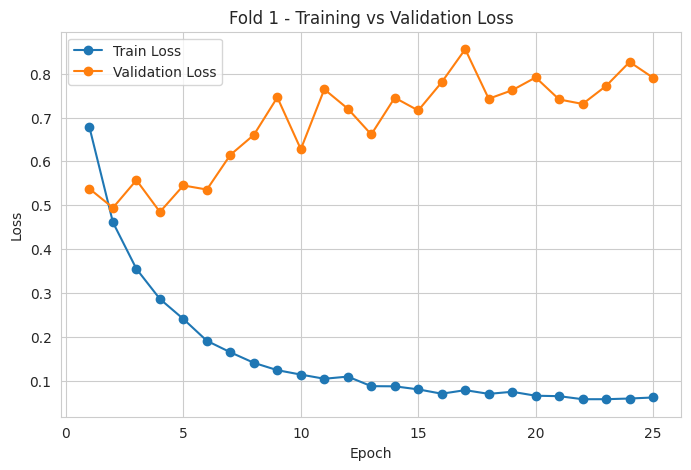

In [17]:
# ambil fold pertama
train_loss = train_loss_history[0]
val_loss = val_loss_history[0]

epochs = range(1, len(train_loss)+1)

plt.figure(figsize=(8,5))

plt.plot(
    epochs,
    train_loss,
    marker='o',
    label='Train Loss'
)

plt.plot(
    epochs,
    val_loss,
    marker='o',
    label='Validation Loss'
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Fold 1 - Training vs Validation Loss")

plt.legend()
plt.grid(True)

plt.show()

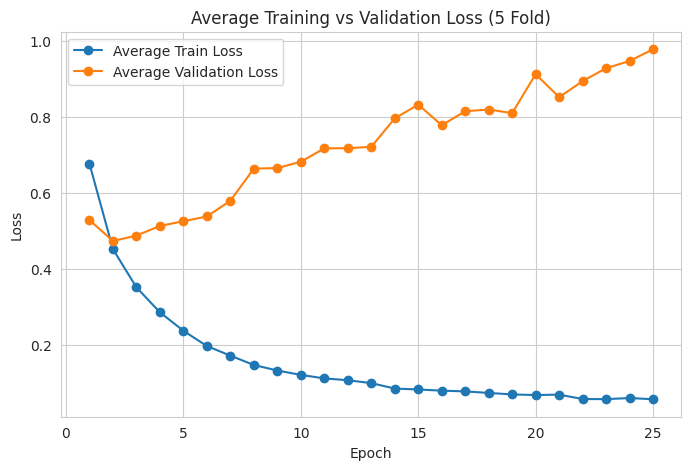

In [18]:
# rata-rata semua fold
avg_train_loss = np.mean(train_loss_history, axis=0)
avg_val_loss = np.mean(val_loss_history, axis=0)

epochs = range(1, len(avg_train_loss)+1)

plt.figure(figsize=(8,5))

plt.plot(
    epochs,
    avg_train_loss,
    marker='o',
    label='Average Train Loss'
)

plt.plot(
    epochs,
    avg_val_loss,
    marker='o',
    label='Average Validation Loss'
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Average Training vs Validation Loss (5 Fold)")

plt.legend()
plt.grid(True)

plt.show()

In [19]:
# ================= HASIL EVALUASI STRATIFIED K-FOLD =================

# Dataframe hasil seluruh fold
df_perf = pd.DataFrame(performance)

# ---------------- Tampilkan hasil tiap fold ----------------
print("\n" + "="*50)
print("HASIL PERFORMA TIAP FOLD")
print("="*50)

print(df_perf.to_string(index=False))


# ---------------- Hitung rata-rata ----------------
mean_scores = df_perf[['accuracy', 'precision', 'recall', 'f1']].mean()

print("\n" + "="*50)
print("RATA-RATA 5 FOLD")
print("="*50)

print(f"Accuracy  : {mean_scores['accuracy']:.4f}")
print(f"Precision : {mean_scores['precision']:.4f}")
print(f"Recall    : {mean_scores['recall']:.4f}")
print(f"F1-Score  : {mean_scores['f1']:.4f}")


# ---------------- Hitung standar deviasi ----------------
std_scores = df_perf[['accuracy', 'precision', 'recall', 'f1']].std()

print("\n" + "="*50)
print("STANDAR DEVIASI 5 FOLD")
print("="*50)

print(f"Accuracy  : {std_scores['accuracy']:.4f}")
print(f"Precision : {std_scores['precision']:.4f}")
print(f"Recall    : {std_scores['recall']:.4f}")
print(f"F1-Score  : {std_scores['f1']:.4f}")


HASIL PERFORMA TIAP FOLD
 fold  accuracy  precision   recall       f1
    1  0.860418   0.802473 0.818661 0.809855
    2  0.861565   0.806119 0.792599 0.798571
    3  0.860418   0.797282 0.796361 0.796530
    4  0.867297   0.809873 0.813804 0.811810
    5  0.864966   0.810332 0.796621 0.802956

RATA-RATA 5 FOLD
Accuracy  : 0.8629
Precision : 0.8052
Recall    : 0.8036
F1-Score  : 0.8039

STANDAR DEVIASI 5 FOLD
Accuracy  : 0.0031
Precision : 0.0055
Recall    : 0.0118
F1-Score  : 0.0067


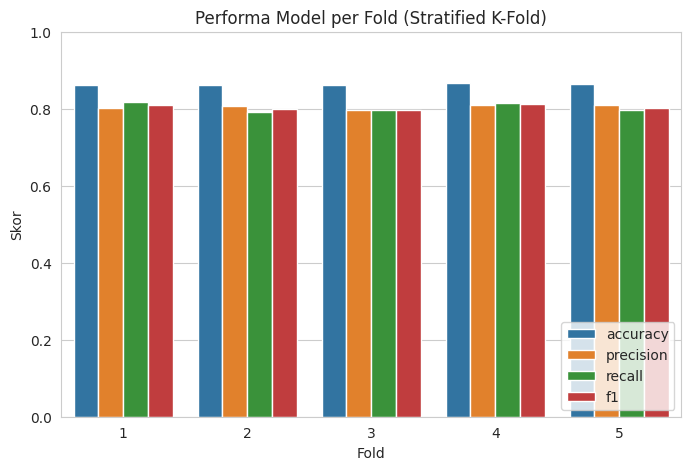

In [20]:
# Visualisasi Performa Tiap Fold
df_melt = df_perf.melt(id_vars='fold', value_vars=['accuracy', 'precision', 'recall', 'f1'],
                        var_name='Metrik', value_name='Skor')

plt.figure(figsize=(8, 5))
sns.barplot(data=df_melt, x='fold', y='Skor', hue='Metrik')
plt.title('Performa Model per Fold (Stratified K-Fold)')
plt.xlabel('Fold')
plt.ylabel('Skor')
plt.ylim(0, 1)
plt.legend(loc='lower right')
plt.show()

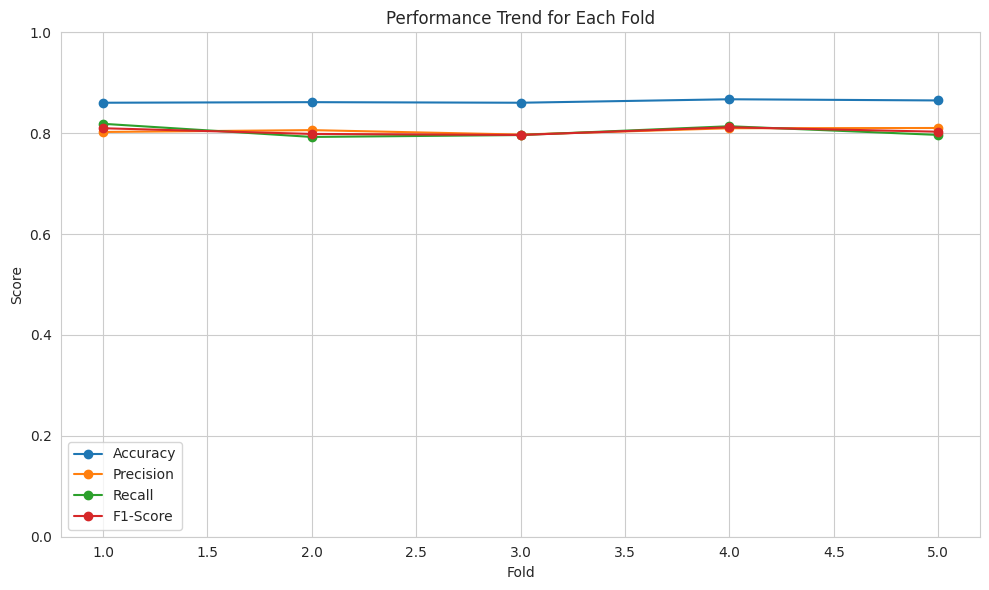

In [21]:
df_perf = pd.DataFrame(performance)

plt.figure(figsize=(10,6))

plt.plot(df_perf['fold'], df_perf['accuracy'], marker='o', label='Accuracy')
plt.plot(df_perf['fold'], df_perf['precision'], marker='o', label='Precision')
plt.plot(df_perf['fold'], df_perf['recall'], marker='o', label='Recall')
plt.plot(df_perf['fold'], df_perf['f1'], marker='o', label='F1-Score')

plt.title('Performance Trend for Each Fold')
plt.xlabel('Fold')
plt.ylabel('Score')
plt.ylim(0,1)

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

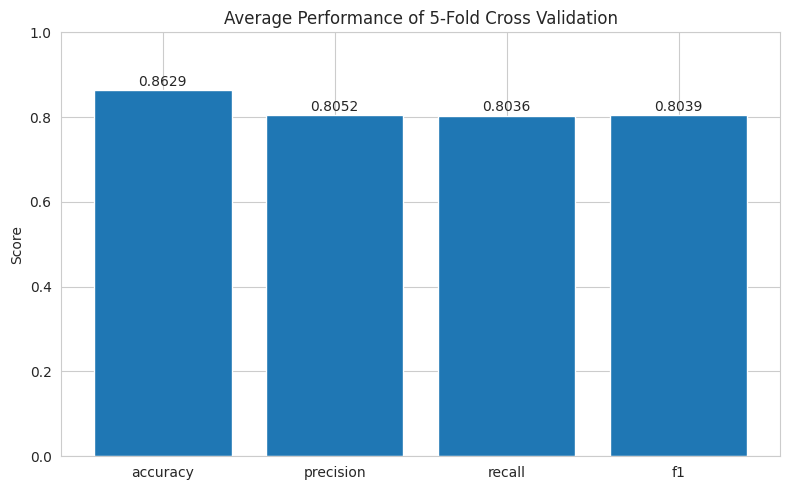

In [22]:
df_perf = pd.DataFrame(performance)

mean_scores = df_perf[
    ['accuracy','precision','recall','f1']
].mean()

plt.figure(figsize=(8,5))

plt.bar(
    mean_scores.index,
    mean_scores.values
)

plt.title('Average Performance of 5-Fold Cross Validation')
plt.ylabel('Score')
plt.ylim(0,1)

for i, v in enumerate(mean_scores.values):
    plt.text(i, v+0.01, f"{v:.4f}", ha='center')

plt.tight_layout()
plt.show()

In [23]:
from sklearn.metrics import (
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("=== Classification Report ===")
print(
    classification_report(
        all_y_true,
        all_y_pred
    )
)

print("\n=== METRIK EVALUASI (MACRO) ===")

accuracy = accuracy_score(
    all_y_true,
    all_y_pred
) * 100

precision = precision_score(
    all_y_true,
    all_y_pred,
    average='macro'
) * 100

recall = recall_score(
    all_y_true,
    all_y_pred,
    average='macro'
) * 100

f1 = f1_score(
    all_y_true,
    all_y_pred,
    average='macro'
) * 100

print(f"Accuracy  : {accuracy:.2f}%")
print(f"Precision : {precision:.2f}%")
print(f"Recall    : {recall:.2f}%")
print(f"F1-Score  : {f1:.2f}%")

=== Classification Report ===
              precision    recall  f1-score   support

           0       0.91      0.91      0.91     10864
           1       0.63      0.61      0.62      2588
           2       0.88      0.89      0.88      3992

    accuracy                           0.86     17444
   macro avg       0.80      0.80      0.80     17444
weighted avg       0.86      0.86      0.86     17444


=== METRIK EVALUASI (MACRO) ===
Accuracy  : 86.29%
Precision : 80.47%
Recall    : 80.36%
F1-Score  : 80.41%



=== AUC ROC ===
Macro AUC    : 90.79%
Weighted AUC : 91.88%


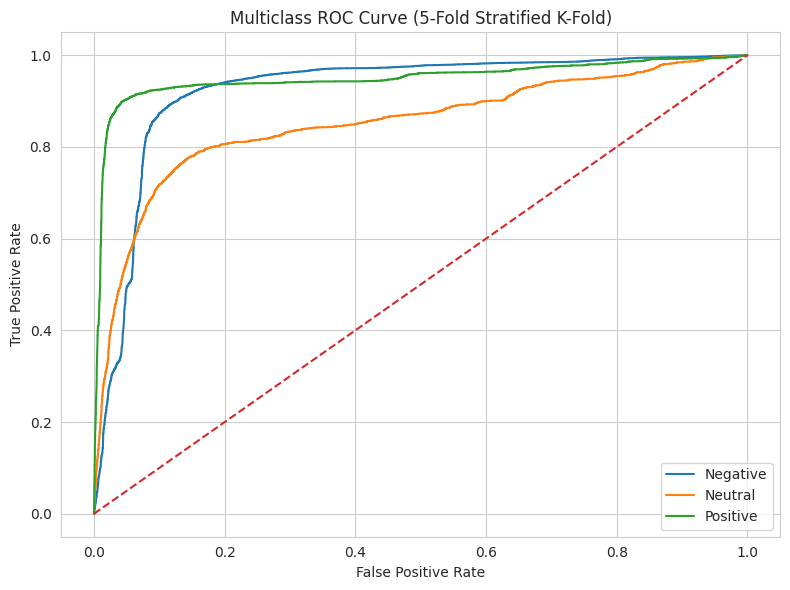

In [24]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_auc_score, roc_curve
import numpy as np
import matplotlib.pyplot as plt

# ubah ke numpy array
all_y_true = np.array(all_y_true)
all_y_probs = np.array(all_y_probs)

# one-hot / binarize label multiclass
y_true_bin = label_binarize(
    all_y_true,
    classes=[0, 1, 2]
)

# hitung AUC
auc_macro = roc_auc_score(
    y_true_bin,
    all_y_probs,
    average='macro',
    multi_class='ovr'
) * 100

auc_weighted = roc_auc_score(
    y_true_bin,
    all_y_probs,
    average='weighted',
    multi_class='ovr'
) * 100


print("\n=== AUC ROC ===")
print(f"Macro AUC    : {auc_macro:.2f}%")
print(f"Weighted AUC : {auc_weighted:.2f}%")


# ---------------- Plot ROC Curve ----------------

plt.figure(figsize=(8,6))

label_map = {
    0: "Negative",
    1: "Neutral",
    2: "Positive"
}

for i in range(3):

    fpr, tpr, _ = roc_curve(
        y_true_bin[:, i],
        all_y_probs[:, i]
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{label_map[i]}"
    )

# diagonal line
plt.plot(
    [0,1],
    [0,1],
    linestyle='--'
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Multiclass ROC Curve (5-Fold Stratified K-Fold)")
plt.legend()

plt.tight_layout()
plt.show()